<a href="https://colab.research.google.com/github/jalvarez2410/PA_Proyecto/blob/main/Programaci%C3%B3n_Avanzada_Proyecto_Jos%C3%A9_Alvarez_1113_24_693.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Avance 1

##Marco

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("camnugent/sandp500")

print("Path to dataset files:", path)

100%|██████████| 19.3M/19.3M [00:00<00:00, 53.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/camnugent/sandp500/versions/4


In [ ]:
import os
import pandas as pd

# Listar los archivos en la ruta de Kaggle
files = os.listdir(path)
print("Archivos encontrados:", files)

# Buscar un archivo CSV para cargar (por ejemplo, 'all_stocks_5yr.csv')
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    # Seleccionamos el primer archivo CSV encontrado
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"\nDataFrame cargado exitosamente desde: {csv_files[0]}")
    display(df.describe())
else:
    print("No se encontraron archivos CSV en la ruta especificada.")

Archivos encontrados: ['merge.sh', 'getSandP.py', 'individual_stocks_5yr', 'all_stocks_5yr.csv']

DataFrame cargado exitosamente desde: all_stocks_5yr.csv


,open,high,low,close,volume
count,619029.000000,619032.000000,619032.000000,619040.000000,6.190400e+05
mean,83.023334,83.778311,82.256096,83.043763,4.321823e+06
std,97.378769,98.207519,96.507421,97.389748,8.693610e+06
min,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,40.220000,40.620000,39.830000,40.245000,1.070320e+06
50%,62.590000,63.150000,62.020000,62.620000,2.082094e+06
75%,94.370000,95.180000,93.540000,94.410000,4.284509e+06
max,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08


#Avance 2

##M1 Probabilidad

In [ ]:
# ============================================
# M1. PREPARACIÓN DE LOS RENDIMIENTOS
# ============================================

import pandas as pd
import numpy as np

# Ordenar los registros por empresa y fecha
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["Name", "date"]).copy()

# Calcular el rendimiento diario de cada acción
df["rendimiento"] = df.groupby("Name")["close"].pct_change()

# Crear una matriz de rendimientos por fecha y empresa
rendimientos = df.pivot(
    index="date",
    columns="Name",
    values="rendimiento"
).sort_index()

print("Empresas disponibles:", rendimientos.shape[1])
print("Fechas disponibles:", rendimientos.shape[0])

display(rendimientos.head())

Empresas disponibles: 505
Fechas disponibles: 1259


Name,A,AAL,AAP,AAPL,ABBV,ABC,ABT,ACN,ADBE,ADI,...,XL,XLNX,XOM,XRAY,XRX,XYL,YUM,ZBH,ZION,ZTS
date,,,,,,,,,,,,,,,,,,,,,
2013-02-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013-02-11,-0.010648,-0.019661,-0.006464,0.010422,-0.011034,-0.002772,-0.004359,-0.003274,-0.012270,0.008315,...,0.002479,-0.001333,-0.003724,-0.000700,0.003769,0.013658,-0.011485,-0.002637,0.002900,0.006354
2013-02-12,0.000448,-0.013140,0.002679,-0.025067,-0.011994,0.004277,0.001168,0.004106,0.006470,0.004123,...,0.003532,0.003203,0.002039,0.000700,-0.003755,0.017844,0.003098,-0.002776,0.011565,0.014432
2013-02-13,0.002913,0.027330,0.004707,-0.001903,-0.004235,-0.006814,0.004665,0.002590,-0.002057,-0.000216,...,0.000352,0.005854,0.002374,0.004899,0.005025,0.011091,-0.005251,0.007423,0.010208,-0.005631
2013-02-14,-0.003799,-0.045703,-0.001646,-0.000899,0.036859,0.002787,0.006965,-0.005846,-0.005153,0.006053,...,-0.007037,0.016931,-0.001692,-0.003946,0.003750,0.007431,-0.008073,0.004474,-0.004446,-0.008346


###Probabilidad marginal

In [ ]:
# ============================================
# M1.1 PROBABILIDAD MARGINAL
# ============================================

# Sustituye estos ejemplos por tus cinco acciones asignadas
acciones = ["AAPL", "MSFT", "AMZN", "JPM", "XOM"]

resultados = []

for accion in acciones:

    if accion not in rendimientos.columns:
        print(f"Advertencia: {accion} no está disponible en el dataset.")
        continue

    r = rendimientos[accion].dropna()

    # Probabilidad de rendimiento positivo
    p_subida = (r > 0).mean()

    # Probabilidad de caída superior al 2 %
    p_caida = (r < -0.02).mean()

    resultados.append({
        "Acción": accion,
        "P(R > 0)": p_subida,
        "P(R < -2 %)": p_caida,
        "Días analizados": len(r)
    })

tabla_marginal = pd.DataFrame(resultados)

display(tabla_marginal.round(4))

,Acción,P(R > 0),P(R < -2 %),Días analizados
0,AAPL,0.5167,0.0700,1258
1,MSFT,0.5207,0.0429,1258
2,AMZN,0.5413,0.0676,1258
3,JPM,0.5207,0.0541,1258
4,XOM,0.4921,0.0366,1258


### Probabilidad conjunta

In [ ]:
# ============================================
# M1.2 PROBABILIDAD CONJUNTA
# ============================================

accion_1 = "AAPL"
accion_2 = "MSFT"

# Seleccionar fechas en las que ambas acciones tienen rendimiento
datos = rendimientos[[accion_1, accion_2]].dropna()

# Definir los eventos
A = datos[accion_1] > 0
B = datos[accion_2] > 0

# Probabilidades marginales
p_A = A.mean()
p_B = B.mean()

# Probabilidad conjunta
p_conjunta = (A & B).mean()

print(f"P({accion_1} sube) = {p_A:.4f}")
print(f"P({accion_2} sube) = {p_B:.4f}")
print(f"P(ambas acciones suben) = {p_conjunta:.4f}")

# Comparación con la independencia
p_independencia = p_A * p_B

print(f"\nProducto P(A) × P(B) = {p_independencia:.4f}")
print(f"Diferencia observada = {p_conjunta - p_independencia:.4f}")

P(AAPL sube) = 0.5167
P(MSFT sube) = 0.5207
P(ambas acciones suben) = 0.3331

Producto P(A) × P(B) = 0.2690
Diferencia observada = 0.0640


###Probabilidad condicional

In [ ]:
# ============================================
# M1.3 PROBABILIDAD CONDICIONAL
# ============================================

accion = "AAPL"

# Obtener los rendimientos válidos de la acción
r = rendimientos[accion].dropna()

# Evento A: la acción sube hoy
sube_hoy = r > 0

# Evento B: la acción sube en la siguiente observación bursátil
sube_siguiente = sube_hoy.shift(-1)

# Eliminar la última observación, que no tiene siguiente día disponible
datos_condicionales = pd.DataFrame({
    "Sube_hoy": sube_hoy,
    "Sube_siguiente": sube_siguiente
}).dropna()

# Probabilidad de subir en la siguiente observación
p_subida = datos_condicionales["Sube_siguiente"].mean()

# Probabilidad condicional: sube después de haber subido
dias_subio_hoy = datos_condicionales[
    datos_condicionales["Sube_hoy"]
]

p_condicional = dias_subio_hoy["Sube_siguiente"].mean()

print(f"Acción analizada: {accion}")
print(f"P(subida en la siguiente jornada) = {p_subida:.4f}")
print(f"P(subida siguiente | subida hoy) = {p_condicional:.4f}")

print("\nComparación:")

if p_condicional > p_subida:
    print("La probabilidad condicional observada es mayor que la probabilidad general.")
elif p_condicional < p_subida:
    print("La probabilidad condicional observada es menor que la probabilidad general.")
else:
    print("Ambas probabilidades son iguales.")

Acción analizada: AAPL
P(subida en la siguiente jornada) = 0.5163
P(subida siguiente | subida hoy) = 0.5000

Comparación:
La probabilidad condicional observada es menor que la probabilidad general.


###Teorema de Bayes

In [ ]:
# ============================================
# M1.4 TEOREMA DE BAYES
# ============================================

accion_A = "AAPL"
accion_B = "MSFT"

# Alinear ambas acciones por fecha y eliminar faltantes
datos_bayes = rendimientos[[accion_A, accion_B]].dropna().copy()

# A: la acción A sube hoy
evento_A = datos_bayes[accion_A] > 0

# B: la acción B sube en la siguiente observación disponible
evento_B = (datos_bayes[accion_B] > 0).shift(-1)

# Construir tabla y eliminar la última observación sin día siguiente
datos_bayes = pd.DataFrame({
    "A": evento_A,
    "B": evento_B
}).dropna()

A = datos_bayes["A"].astype(bool)
B = datos_bayes["B"].astype(bool)

# Probabilidades necesarias
p_A = A.mean()
p_B = B.mean()
p_A_y_B = (A & B).mean()

# Probabilidad de B dado A
p_B_dado_A = (A & B).sum() / A.sum() if A.sum() > 0 else np.nan

# Aplicar Bayes
if p_B > 0 and not np.isnan(p_B_dado_A):
    p_A_dado_B = (p_B_dado_A * p_A) / p_B

    print("APLICACIÓN DEL TEOREMA DE BAYES")
    print(f"P(A) = {p_A:.4f}")
    print(f"P(B) = {p_B:.4f}")
    print(f"P(A y B) = {p_A_y_B:.4f}")
    print(f"P(B | A) = {p_B_dado_A:.4f}")
    print(f"P(A | B) = {p_A_dado_B:.4f}")

    # Comprobación directa
    p_directa = (A & B).sum() / B.sum() if B.sum() > 0 else np.nan

    print(f"\nComprobación directa de P(A | B) = {p_directa:.4f}")
else:
    print("No es posible aplicar Bayes: P(B) es cero o no hay observaciones suficientes.")

APLICACIÓN DEL TEOREMA DE BAYES
P(A) = 0.5171
P(B) = 0.5203
P(A y B) = 0.2625
P(B | A) = 0.5077
P(A | B) = 0.5046

Comprobación directa de P(A | B) = 0.5046


##M2 Variables aleatorias y momentos

###Esperanza

In [ ]:
# ============================================
# M2.1 ESPERANZA MATEMÁTICA
# ============================================

# Seleccionar las acciones asignadas
acciones = ["AAPL", "MSFT", "AMZN", "JPM", "XOM"]

resultados_esperanza = []

for accion in acciones:

    if accion not in rendimientos.columns:
        print(f"La acción {accion} no está disponible.")
        continue

    # Obtener rendimientos válidos
    datos = rendimientos[accion].dropna()

    # Calcular la esperanza matemática
    esperanza = datos.mean()

    resultados_esperanza.append({
        "Acción": accion,
        "Esperanza diaria": esperanza,
        "Esperanza diaria (%)": esperanza * 100
    })

# Crear tabla de resultados
tabla_esperanza = pd.DataFrame(resultados_esperanza)

display(tabla_esperanza.round(6))

,Acción,Esperanza diaria,Esperanza diaria (%)
0,AAPL,0.000786,0.078620
1,MSFT,0.001039,0.103887
2,AMZN,0.001508,0.150753
3,JPM,0.000752,0.075192
4,XOM,-0.000051,-0.005145


###Varianza

In [ ]:
# ============================================
# M2.2 VARIANZA DE LOS RENDIMIENTOS
# ============================================

acciones = ["AAPL", "MSFT", "AMZN", "JPM", "XOM"]

resultados_varianza = []

for accion in acciones:

    if accion not in rendimientos.columns:
        print(f"La acción {accion} no está disponible.")
        continue

    datos = rendimientos[accion].dropna()

    # Calcular varianza muestral
    varianza = datos.var(ddof=1)

    # Calcular desviación estándar
    desviacion = datos.std(ddof=1)

    resultados_varianza.append({
        "Acción": accion,
        "Varianza": varianza,
        "Desviación estándar diaria": desviacion,
        "Desviación estándar (%)": desviacion * 100
    })

tabla_varianza = pd.DataFrame(resultados_varianza)

display(tabla_varianza.round(6))

,Acción,Varianza,Desviación estándar diaria,Desviación estándar (%)
0,AAPL,0.000213,0.014593,1.459301
1,MSFT,0.000202,0.014210,1.421017
2,AMZN,0.000333,0.018235,1.823479
3,JPM,0.000165,0.012844,1.284449
4,XOM,0.000122,0.011026,1.102621


###Asimetría

In [ ]:
# ============================================
# M2.3 ASIMETRÍA DE LOS RENDIMIENTOS
# ============================================

acciones = ["AAPL", "MSFT", "AMZN", "JPM", "XOM"]

resultados_asimetria = []

for accion in acciones:

    if accion not in rendimientos.columns:
        print(f"La acción {accion} no está disponible.")
        continue

    datos = rendimientos[accion].dropna()

    # Calcular asimetría muestral
    asimetria = datos.skew()

    # Clasificar la asimetría
    if asimetria > 0.05:
        interpretacion = "Asimetría positiva"
    elif asimetria < -0.05:
        interpretacion = "Asimetría negativa"
    else:
        interpretacion = "Asimetría cercana a cero"

    resultados_asimetria.append({
        "Acción": accion,
        "Asimetría": asimetria,
        "Interpretación": interpretacion
    })

tabla_asimetria = pd.DataFrame(resultados_asimetria)

display(tabla_asimetria.round(4))

,Acción,Asimetría,Interpretación
0,AAPL,0.0118,Asimetría cercana a cero
1,MSFT,0.0539,Asimetría positiva
2,AMZN,0.7076,Asimetría positiva
3,JPM,0.0353,Asimetría cercana a cero
4,XOM,-0.0712,Asimetría negativa


###Curtosis

In [ ]:
# ============================================
# M2.4 CURTOSIS DE LOS RENDIMIENTOS
# ============================================

acciones = ["AAPL", "MSFT", "AMZN", "JPM", "XOM"]

resultados_curtosis = []

for accion in acciones:

    if accion not in rendimientos.columns:
        print(f"La acción {accion} no está disponible.")
        continue

    datos = rendimientos[accion].dropna()

    # Calcular curtosis en exceso
    curtosis = datos.kurt()

    # Interpretar el resultado
    if curtosis > 0:
        interpretacion = "Curtosis en exceso positiva"
    elif curtosis < 0:
        interpretacion = "Curtosis en exceso negativa"
    else:
        interpretacion = "Curtosis en exceso igual a cero"

    resultados_curtosis.append({
        "Acción": accion,
        "Curtosis en exceso": curtosis,
        "Interpretación": interpretacion
    })

tabla_curtosis = pd.DataFrame(resultados_curtosis)

display(tabla_curtosis.round(4))

,Acción,Curtosis en exceso,Interpretación
0,AAPL,3.7847,Curtosis en exceso positiva
1,MSFT,10.7357,Curtosis en exceso positiva
2,AMZN,12.0209,Curtosis en exceso positiva
3,JPM,3.3917,Curtosis en exceso positiva
4,XOM,3.5294,Curtosis en exceso positiva


##M3 Independencia y correlación

###Correlación de Pearson

Matriz de correlación de Pearson


Name,A,AAL,AAP,AAPL,ABBV,ABC,ABT,ACN,ADBE,ADI
Name,,,,,,,,,,
A,1.0000,0.2922,0.1858,0.2757,0.3520,0.2321,0.4588,0.4224,0.3842,0.4168
AAL,0.2922,1.0000,0.1913,0.2100,0.2253,0.2315,0.2903,0.2876,0.3012,0.3128
AAP,0.1858,0.1913,1.0000,0.1279,0.2111,0.1629,0.2789,0.2085,0.1722,0.1994
AAPL,0.2757,0.2100,0.1279,1.0000,0.1819,0.1394,0.2664,0.2975,0.2919,0.4029
ABBV,0.3520,0.2253,0.2111,0.1819,1.0000,0.3363,0.4316,0.2742,0.2925,0.2888
ABC,0.2321,0.2315,0.1629,0.1394,0.3363,1.0000,0.3580,0.2685,0.2050,0.1939
ABT,0.4588,0.2903,0.2789,0.2664,0.4316,0.3580,1.0000,0.4436,0.3742,0.3619
ACN,0.4224,0.2876,0.2085,0.2975,0.2742,0.2685,0.4436,1.0000,0.4149,0.4100
ADBE,0.3842,0.3012,0.1722,0.2919,0.2925,0.2050,0.3742,0.4149,1.0000,0.4371


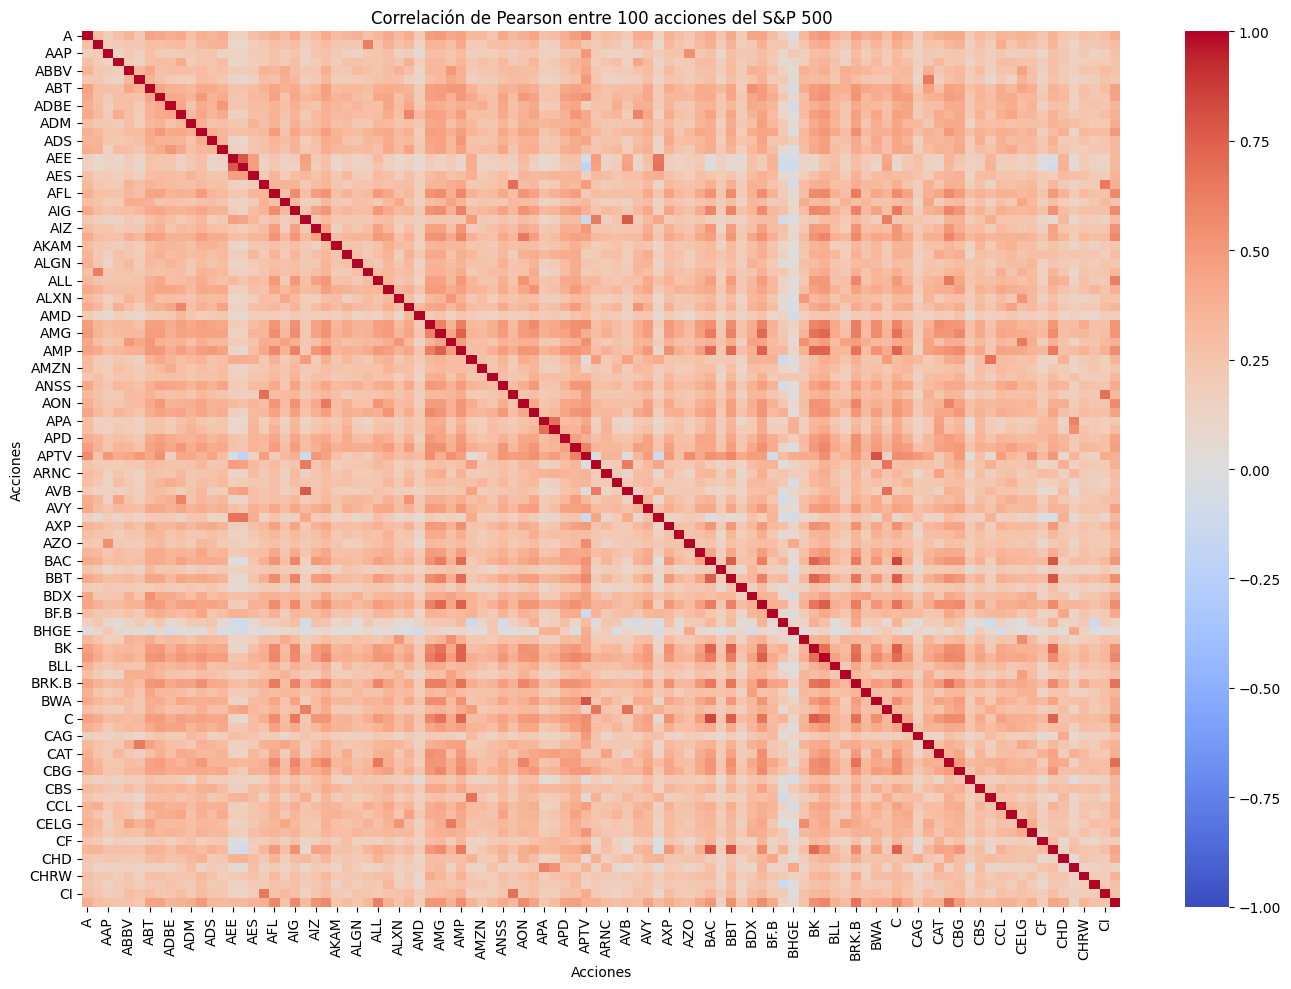


Cinco pares con mayor correlación positiva:


,,Correlación
Name,Name,
BAC,C,0.851071
APTV,BWA,0.799865
BBT,CFG,0.790120
BAC,CFG,0.787704
AEE,AEP,0.777210



Cinco pares con mayor correlación negativa:


,,Correlación
Name,Name,
APTV,AWK,-0.103699
BHF,CHTR,-0.105777
AMT,BHF,-0.110713
AIV,APTV,-0.123450
AEP,APTV,-0.206284


In [ ]:
# ============================================
# M3.1 CORRELACIÓN DE PEARSON
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar al menos 100 acciones disponibles
acciones_100 = sorted(rendimientos.columns)[:100]

# Crear matriz de rendimientos
datos_pearson = rendimientos[acciones_100]

# Calcular matriz de correlación de Pearson
matriz_pearson = datos_pearson.corr(method="pearson")

# Mostrar una parte de la matriz
print("Matriz de correlación de Pearson")
display(matriz_pearson.iloc[:10, :10].round(4))

# Crear mapa de calor
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_pearson,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlación de Pearson entre 100 acciones del S&P 500")
plt.xlabel("Acciones")
plt.ylabel("Acciones")
plt.tight_layout()
plt.show()

# Identificar las correlaciones más altas entre acciones diferentes
correlaciones = matriz_pearson.where(
    np.triu(np.ones(matriz_pearson.shape), k=1).astype(bool)
).stack().sort_values(ascending=False)

print("\nCinco pares con mayor correlación positiva:")
display(correlaciones.head(5).rename("Correlación").to_frame())

print("\nCinco pares con mayor correlación negativa:")
display(correlaciones.tail(5).rename("Correlación").to_frame())

###Correlación de Spearman

Matriz de correlación de Spearman


Name,A,AAL,AAP,AAPL,ABBV,ABC,ABT,ACN,ADBE,ADI
Name,,,,,,,,,,
A,1.0000,0.3474,0.3017,0.3083,0.4342,0.3519,0.5130,0.5181,0.4900,0.4913
AAL,0.3474,1.0000,0.2518,0.2306,0.2408,0.2761,0.2977,0.2909,0.3344,0.3374
AAP,0.3017,0.2518,1.0000,0.1779,0.2593,0.2441,0.3008,0.3067,0.2909,0.2567
AAPL,0.3083,0.2306,0.1779,1.0000,0.1998,0.1914,0.2852,0.3022,0.3550,0.4201
ABBV,0.4342,0.2408,0.2593,0.1998,1.0000,0.3802,0.4842,0.3303,0.3618,0.3221
ABC,0.3519,0.2761,0.2441,0.1914,0.3802,1.0000,0.4060,0.3374,0.3327,0.2832
ABT,0.5130,0.2977,0.3008,0.2852,0.4842,0.4060,1.0000,0.4829,0.4296,0.3962
ACN,0.5181,0.2909,0.3067,0.3022,0.3303,0.3374,0.4829,1.0000,0.5094,0.4526
ADBE,0.4900,0.3344,0.2909,0.3550,0.3618,0.3327,0.4296,0.5094,1.0000,0.4874


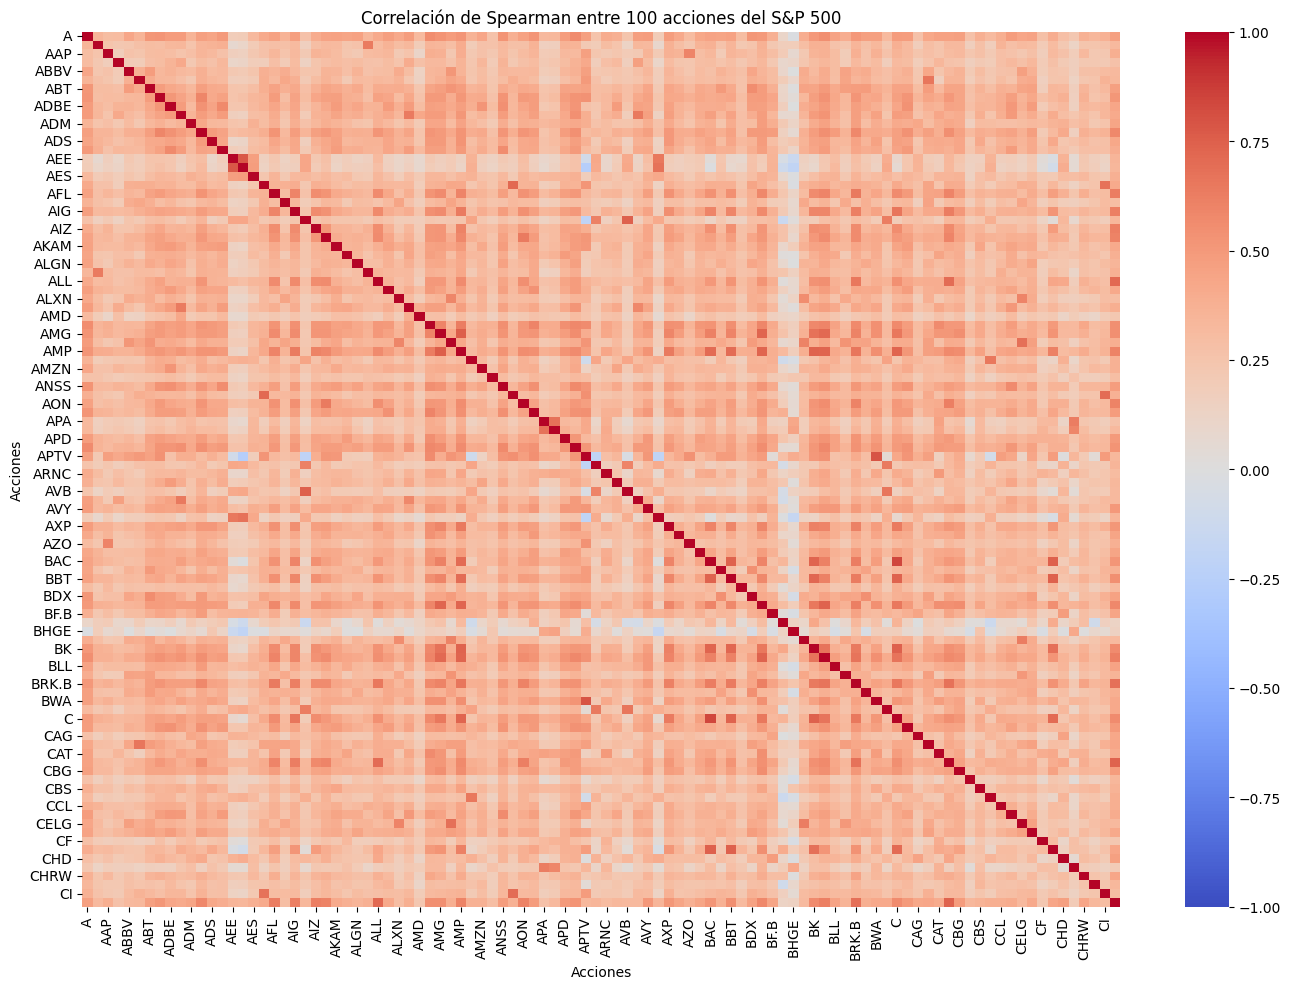


Comparación entre dos acciones
Acciones: AAPL y MSFT
Correlación de Pearson: 0.3666
Correlación de Spearman: 0.3720
Diferencia absoluta: 0.0054


In [ ]:
# ============================================
# M3.2 CORRELACIÓN DE SPEARMAN
# ============================================

# Seleccionar las mismas 100 acciones
acciones_100 = sorted(rendimientos.columns)[:100]

datos_spearman = rendimientos[acciones_100]

# Calcular matriz de correlación de Spearman
matriz_spearman = datos_spearman.corr(method="spearman")

print("Matriz de correlación de Spearman")
display(matriz_spearman.iloc[:10, :10].round(4))

# Graficar mapa de calor
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_spearman,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlación de Spearman entre 100 acciones del S&P 500")
plt.xlabel("Acciones")
plt.ylabel("Acciones")
plt.tight_layout()
plt.show()

# Comparar Pearson y Spearman para dos acciones
accion_1 = "AAPL"
accion_2 = "MSFT"

datos_dos = rendimientos[[accion_1, accion_2]].dropna()

pearson = datos_dos[accion_1].corr(
    datos_dos[accion_2],
    method="pearson"
)

spearman = datos_dos[accion_1].corr(
    datos_dos[accion_2],
    method="spearman"
)

print("\nComparación entre dos acciones")
print(f"Acciones: {accion_1} y {accion_2}")
print(f"Correlación de Pearson: {pearson:.4f}")
print(f"Correlación de Spearman: {spearman:.4f}")
print(f"Diferencia absoluta: {abs(pearson - spearman):.4f}")

###Chi cuadrado

In [ ]:
# ============================================
# M3.3 PRUEBA CHI-CUADRADO DE INDEPENDENCIA
# ============================================

from scipy.stats import chi2_contingency

# Seleccionar dos acciones
accion_1 = "AAPL"
accion_2 = "MSFT"

# Alinear las observaciones por fecha
datos_chi = rendimientos[[accion_1, accion_2]].dropna().copy()

# Clasificar los rendimientos
datos_chi["Estado_A"] = np.where(
    datos_chi[accion_1] > 0,
    "Sube",
    "No sube"
)

datos_chi["Estado_B"] = np.where(
    datos_chi[accion_2] > 0,
    "Sube",
    "No sube"
)

# Crear tabla de contingencia
tabla_contingencia = pd.crosstab(
    datos_chi["Estado_A"],
    datos_chi["Estado_B"]
)

print("Tabla de contingencia")
display(tabla_contingencia)

# Aplicar prueba chi-cuadrado
chi2, p_valor, grados_libertad, esperadas = chi2_contingency(
    tabla_contingencia
)

# Mostrar resultados
print("\nResultados de la prueba chi-cuadrado")
print(f"Estadístico chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Valor p: {p_valor:.6f}")

# Mostrar frecuencias esperadas
tabla_esperadas = pd.DataFrame(
    esperadas,
    index=tabla_contingencia.index,
    columns=tabla_contingencia.columns
)

print("\nFrecuencias esperadas")
display(tabla_esperadas.round(2))

# Verificar las frecuencias esperadas
if (esperadas < 5).any():
    print(
        "\nAdvertencia: hay frecuencias esperadas menores que 5. "
        "La aproximación chi-cuadrado puede no ser adecuada."
    )

# Interpretar los resultados
alpha = 0.05

print("\nInterpretación estadística")

if p_valor < alpha:
    print(
        "Se rechaza H0. Existe evidencia estadística de asociación "
        "entre las categorías de movimiento de ambas acciones."
    )
else:
    print(
        "No se rechaza H0. No se encontró evidencia estadística "
        "suficiente para afirmar que existe asociación."
    )

Tabla de contingencia


Estado_B,No sube,Sube
Estado_A,,
No sube,372,236
Sube,231,419



Resultados de la prueba chi-cuadrado
Estadístico chi-cuadrado: 81.7641
Grados de libertad: 1
Valor p: 0.000000

Frecuencias esperadas


Estado_B,No sube,Sube
Estado_A,,
No sube,291.43,316.57
Sube,311.57,338.43



Interpretación estadística
Se rechaza H0. Existe evidencia estadística de asociación entre las categorías de movimiento de ambas acciones.


#Declaración de uso de IA
Se emplearon herramientas de IA generativa ChatGPT únicamente como apoyo en la [depuración / optimización / documentación] del código. Todo el flujo de datos y análisis fue verificado y validado por los autores, quienes asumen la responsabilidad total de la lógica, ejecuciones y resultados.